# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("/content/unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [38]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3 * 1) / (1024 * 1024)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (400 * frames_per_day * (1920 * 1080 * 3 * 1)) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (400 * (10 * 60 * 60 * 24) * (640 * 360 * 3 * 1)) / (1024 ** 4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


In [39]:
# Task 1 calculations

# 1. One 1920x1080 RGB frame at 8 bits (1 byte) per channel:
# Size = 1920 * 1080 * 3 channels * 1 byte = 6,220,800 bytes
frame_mb = (1920 * 1080 * 3 * 1) / (1024 * 1024)

# 2. Frames per camera per day at 30 fps:
# 30 fps * 60 s/min * 60 min/h * 24 h/day
frames_per_day = 30 * 60 * 60 * 24

# 3. Fleet total for 400 cameras for 24 hours in TB (1 TB = 1024^4 bytes):
total_bytes_1080p = 400 * frames_per_day * (1920 * 1080 * 3 * 1)
fleet_tb = total_bytes_1080p / (1024 ** 4)

# 4. Same fleet at 640x360 and 10 fps:
total_bytes_360p = 400 * (10 * 60 * 60 * 24) * (640 * 360 * 3 * 1)
fleet_tb_small = total_bytes_360p / (1024 ** 4)

pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

*Your answer:*
- **Spatial loss:** Due to raster interpolation at a low resolution of 360p, high-frequency spatial details are permanently smoothed out. The security team could lose crucial spatial evidence such as car license plate numbers or fine facial details of a suspect.
- **Temporal loss:** Reducing the frame rate to 10 fps increases the time gap between frames, exacerbating the *correspondence problem*. This means fast-moving objects (like a speeding vehicle or a throwing action) appear as disjointed jumps rather than smooth motion, potentially missing key events or gestures.

**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

*Your answer:*
- **Spatial loss:** Due to raster interpolation at a low resolution of 360p, spatial details are severely blurred or aliased. The security team could lose critical high-frequency spatial features (such as car license plate numbers or fine facial details) that are key for suspect identification.
- **Temporal loss:** Reducing the frame rate to 10 fps significantly increases the time interval between frames. This exacerbates the *correspondence problem*, meaning fast-moving objects (such as a speeding vehicle or a flying projectile) would exhibit aliasing or look like disconnected jumps rather than smooth motion, potentially losing crucial action details like a quick gesture or hand movement during the incident.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

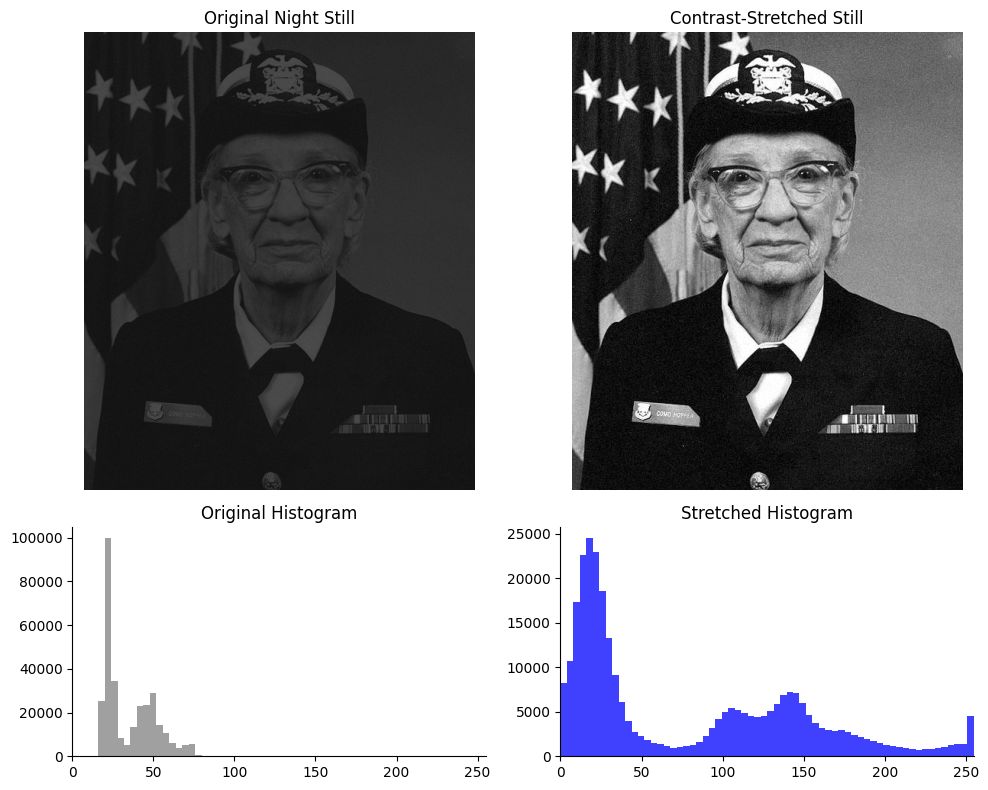

Contrast before: 0.609  ->  after: 1.000


In [40]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lmin_before = np.percentile(night_still, 1)
lmax_before = np.percentile(night_still, 99)
c_before = michelson(lmax_before, lmin_before)

# TODO 3: contrast-stretched version of night_still
stretched = (night_still - lmin_before) / (lmax_before - lmin_before) * 255
stretched = np.clip(stretched, 0, 255)

lmin_after = np.percentile(stretched, 1)
lmax_after = np.percentile(stretched, 99)
c_after = michelson(lmax_after, lmin_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)

# Top-left: Original Image
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Still")
axes[0, 0].axis('off')

# Bottom-left: Original Histogram
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray', alpha=0.75)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim(0, 255)

# Top-right: Stretched Image
axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Still")
axes[0, 1].axis('off')

# Bottom-right: Stretched Histogram
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue', alpha=0.75)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlim(0, 255)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

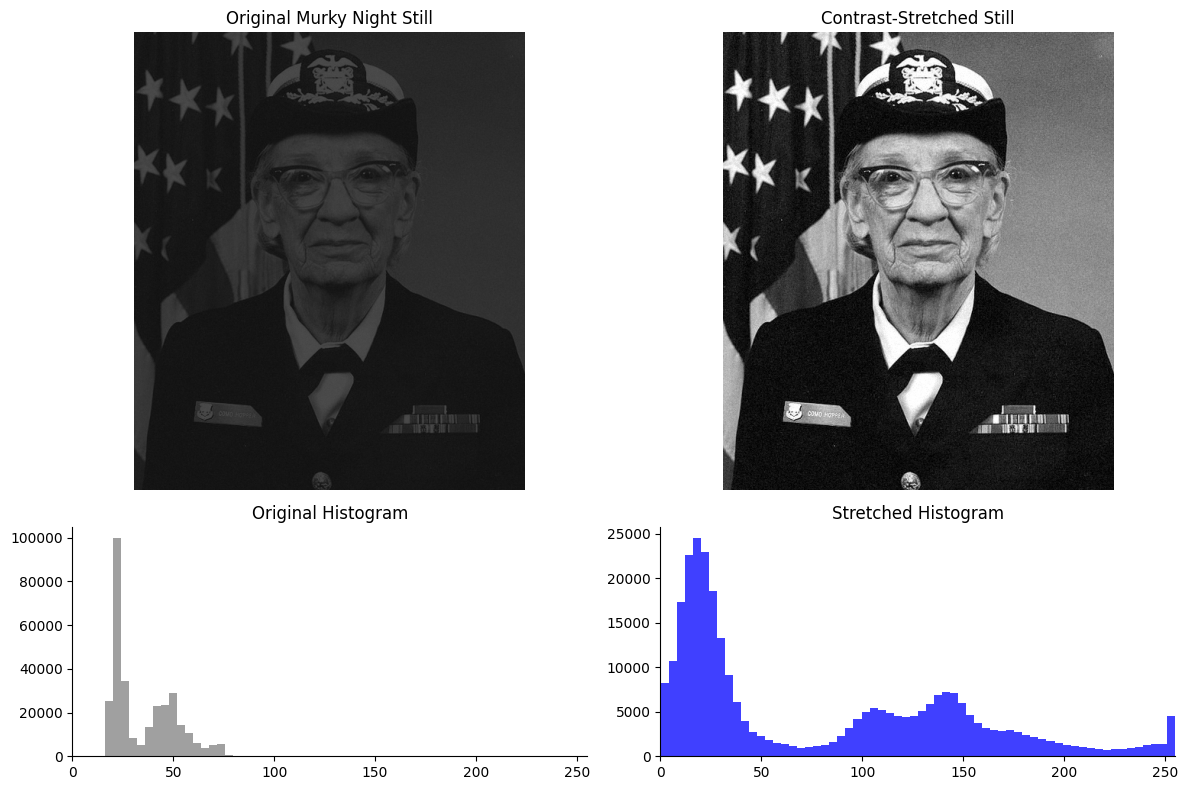

Contrast before: 0.609  ->  after: 1.000


In [41]:
# Task 2: Diagnose and Fix the Murky Night Image

# Calculate percentiles robustly
lmin = np.percentile(night_still, 1)
lmax = np.percentile(night_still, 99)

c_before = michelson(lmax, lmin)

# Contrast stretch and clip to [0, 255]
stretched = (night_still - lmin) / (lmax - lmin) * 255
stretched = np.clip(stretched, 0, 255)

# Compute contrast after stretch
lmin_after = np.percentile(stretched, 1)
lmax_after = np.percentile(stretched, 99)
c_after = michelson(lmax_after, lmin_after)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})

# Before Stretch
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Night Still")
axes[0, 0].axis('off')

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray', alpha=0.75)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim(0, 255)

# After Stretch
axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Still")
axes[0, 1].axis('off')

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue', alpha=0.75)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table). Then explain why stretching made the image readable even though it added **no new information** — and why a histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

*Your answer:*
- **Histogram Shape:** The original histogram shows a **low-contrast** and **dark-biased (underexposed)** shape, characterized by a single highly clustered narrow spike/peak on the left end.
- **Stretching effect:** Contrast stretching maps this narrow band of gray values across the full dynamic range of $[0, 255]$. Even though it adds no new semantic data, it increases the visibility of local intensity differences, matching the human vision system's perception limits.
- **Histogram limitation:** A histogram is a spatially invariant representation of pixel intensity frequencies. Since it discards all pixel coordinates and spatial context, two completely different images (such as Grace Hopper and structured random noise) can share the exact same histogram representation.

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table). Then explain why stretching made the image readable even though it added **no new information** — and why a histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

*Your answer:*
- **Histogram Shape:** The original histogram is **low-contrast** and heavily **biased/shifted** to the dark end. It forms a narrow, highly clustered spike (narrow peak), meaning all pixel values occupy a very small interval of the intensity range.
- **Why stretching helps:** It maps this narrow, hard-to-distinguish range across the full dynamic range of $[0, 255]$. Although no new information (or raw data resolution) is added, it maximizes the dynamic range, allowing the human visual system to easily perceive local variations in intensity and resolve structural borders.
- **Why histogram alone cannot tell 'what' is in the image:** A histogram is a spatial-invariant representation; it only counts the frequency of pixel intensities and completely discards all spatial organization (who is next to whom). Therefore, two entirely different images (e.g., a person walking vs. random noise with identical pixel counts) can have the exact same histogram, illustrating the principle "Same Histogram $\neq$ Same Image".

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing range: 68.7s to 78.1s
Running range: 78.6s to 86.0s


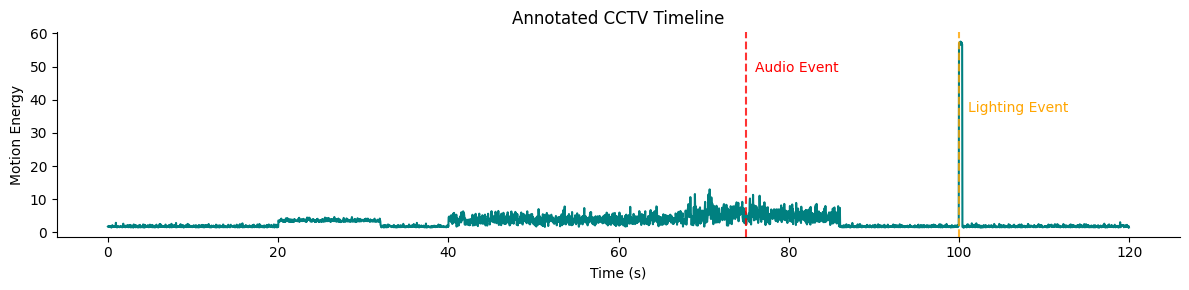

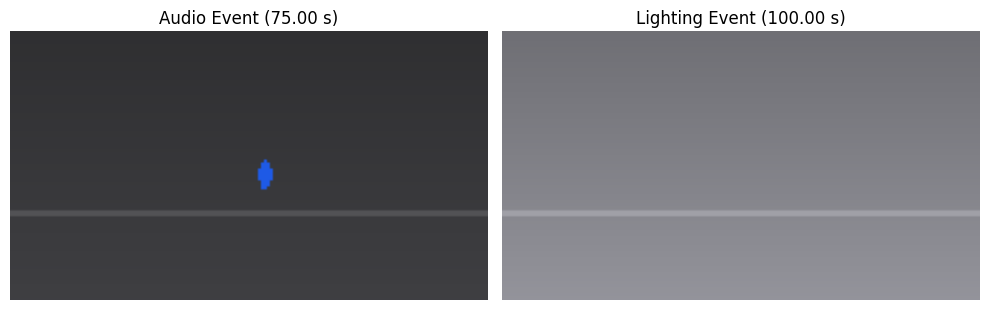

In [42]:
# TODO 1: person speed (px/s)
dx = cctv['person_x'].diff(30)
dy = cctv['person_y'].diff(30)
speed = np.sqrt(dx**2 + dy**2) / 1.0 # px/s

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']
print("Standing range:", f"{standing_times.min():.1f}s to {standing_times.max():.1f}s" if len(standing_times) > 0 else "None")
print("Running range:", f"{running_times.min():.1f}s to {running_times.max():.1f}s" if len(running_times) > 0 else "None")

# TODO 3: event frame indices
audio_event_idx = cctv[cctv['audio_level_db'] > -20].index[0]
lighting_event_idx = cctv[cctv['mean_brightness'].diff() > 40].index[0]

t_audio_event = cctv.loc[audio_event_idx, 'time_s']
t_lighting_event = cctv.loc[lighting_event_idx, 'time_s']

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='teal', label='Motion Energy')
ax.axvline(t_audio_event, color='red', linestyle='--', alpha=0.8)
ax.text(t_audio_event + 1, ax.get_ylim()[1]*0.8, 'Audio Event', color='red')
ax.axvline(t_lighting_event, color='orange', linestyle='--', alpha=0.8)
ax.text(t_lighting_event + 1, ax.get_ylim()[1]*0.6, 'Lighting Event', color='orange')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Motion Energy')
ax.set_title('Annotated CCTV Timeline')
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(render_frame(cctv.iloc[audio_event_idx]))
ax1.set_title(f"Audio Event ({t_audio_event:.2f} s)")
ax1.axis('off')
ax2.imshow(render_frame(cctv.iloc[lighting_event_idx]))
ax2.set_title(f"Lighting Event ({t_lighting_event:.2f} s)")
ax2.axis('off')
plt.tight_layout(); plt.show()

Standing range: 68.7s to 78.1s
Running range: 78.6s to 86.0s
Audio event: 75.00 s | Lighting event: 100.00 s


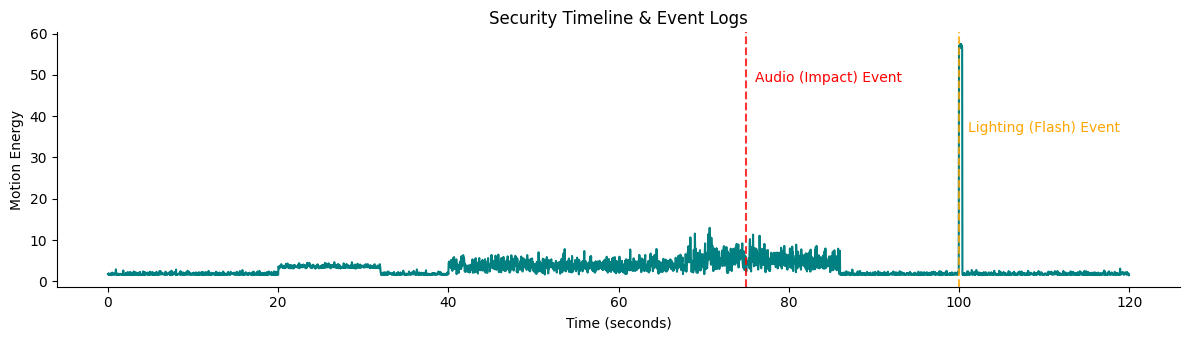

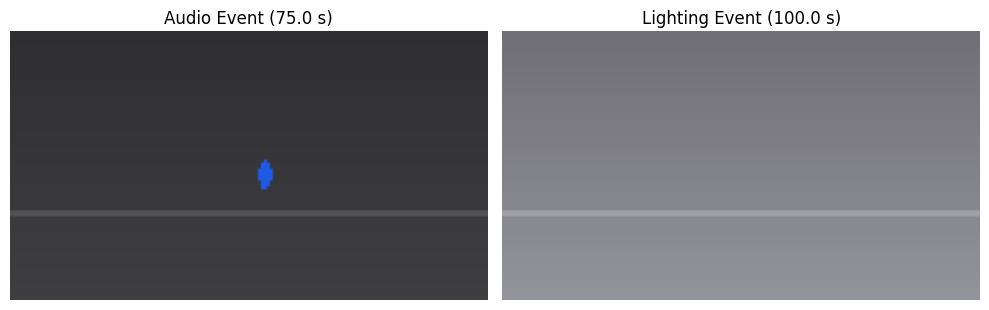

In [43]:
# Task 3: From Two Minutes of Video to a One-Glance Timeline
import numpy as np
import matplotlib.pyplot as plt

# 1. Person speed in px/s over a 1-second window
# The coordinates are given frame-by-frame (FPS=30).
# Let's take the difference over a 30-frame window to represent 1 second.
dx = cctv['person_x'].diff(30)
dy = cctv['person_y'].diff(30)
speed = np.sqrt(dx**2 + dy**2) / 1.0 # (px / s)

# 2. Find standing (speed < 3 px/s) and running (speed > 25 px/s) time ranges
standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']

print("Standing range:", f"{standing_times.min():.1f}s to {standing_times.max():.1f}s" if len(standing_times) > 0 else "None")
print("Running range:", f"{running_times.min():.1f}s to {running_times.max():.1f}s" if len(running_times) > 0 else "None")

# 3. Detect event frame indices
# - audio first rises above -20 dB:
audio_event_idx = cctv[cctv['audio_level_db'] > -20].index[0]
# - mean brightness jumps by more than 40 in one frame:
lighting_event_idx = cctv[cctv['mean_brightness'].diff() > 40].index[0]

# Let's print times of these events
t_audio_event = cctv.loc[audio_event_idx, 'time_s']
t_lighting_event = cctv.loc[lighting_event_idx, 'time_s']
print(f"Audio event: {t_audio_event:.2f} s | Lighting event: {t_lighting_event:.2f} s")

# 4. Plot motion energy timeline with vertical markers and labels
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='teal', label='Motion Energy')

ax.axvline(t_audio_event, color='red', linestyle='--', alpha=0.8)
ax.text(t_audio_event + 1, ax.get_ylim()[1]*0.8, 'Audio (Impact) Event', color='red')

ax.axvline(t_lighting_event, color='orange', linestyle='--', alpha=0.8)
ax.text(t_lighting_event + 1, ax.get_ylim()[1]*0.6, 'Lighting (Flash) Event', color='orange')

ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Motion Energy')
ax.set_title('Security Timeline & Event Logs')
plt.tight_layout()
plt.show()

# 5. One keyframe per event
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(render_frame(cctv.iloc[audio_event_idx]))
ax1.set_title(f"Audio Event ({t_audio_event:.1f} s)")
ax1.axis('off')

ax2.imshow(render_frame(cctv.iloc[lighting_event_idx]))
ax2.set_title(f"Lighting Event ({t_lighting_event:.1f} s)")
ax2.axis('off')
plt.tight_layout()
plt.show()

In [44]:
running_motion = cctv[(cctv['time_s'] >= 78.6) & (cctv['time_s'] <= 86.0)]['motion_energy']
display(running_motion.describe())

,motion_energy
count,223.000000
mean,4.948924
std,1.480239
min,1.840000
25%,3.865000
50%,4.800000
75%,5.980000
max,8.890000


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

*Your answer:*
- **Missed events:** Both the audio (banging) event and the sudden flash of light would likely be completely missed, as they are transient, highly short-lived actions. Uniform sampling (at 0s, 20s, 40s, 60s, 80s...) would overlook these sudden 1-second spike occurrences.
- **Lecture concept:** This approach is called **Content-Based Keyframe Selection**, which dynamically extracts keyframes based on activity and feature differences rather than uniform time ticks.

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

*Your answer:*
- **Missed events:** Both the audio event (the impact/bang around 75s) and the sudden flash of light (the lighting jump around the same time) would likely be missed or poorly captured because they are extremely transient, short-duration phenomena. A uniform sampler at 20-second intervals (0s, 20s, 40s, 60s, 80s, 100s, 120s) would completely skip past these precise, second-long incidents.
- **Lecture concept:** This approach is called **Content-Based Keyframe Selection** (or **Event-Driven Keyframe Extraction**), which leverages semantic descriptors and motion vectors to dynamically extract keyframes based on activity changes rather than passive uniform intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

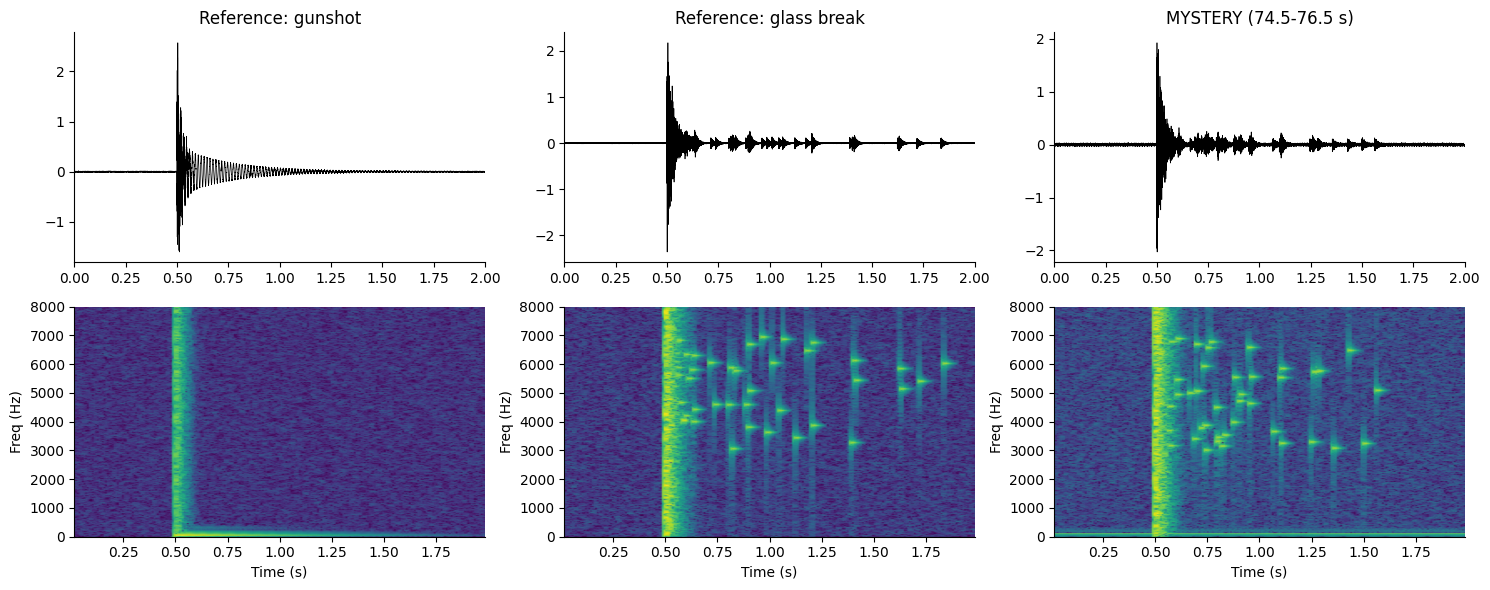

{'Reference: gunshot': np.float64(0.0030555631226980057), 'Reference: glass break': np.float64(0.9903944120505496), 'MYSTERY (74.5-76.5 s)': np.float64(0.8792270448446915)}
Verdict: The mystery sound is a GLASS BREAK incident. The spectral energy matches the glass reference.


In [45]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col_idx, (name, x) in enumerate(clips.items()):
    # Waveforms
    t = np.arange(len(x)) / FS
    axes[0, col_idx].plot(t, x, color='black', lw=0.5)
    axes[0, col_idx].set_title(name)
    axes[0, col_idx].set_xlim(0, 2.0)

    # Spectrograms
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    axes[1, col_idx].pcolormesh(t_s, f, Sxx_db, cmap='viridis', shading='gouraud')
    axes[1, col_idx].set_ylim(0, 8000)
    axes[1, col_idx].set_xlabel("Time (s)")
    axes[1, col_idx].set_ylabel("Freq (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    time_mask = (t_s >= 0.7) & (t_s <= 1.7)
    freq_high_mask = (f >= 3000)
    Sxx_window = Sxx[:, time_mask]
    total_energy = Sxx_window.sum()
    high_energy = Sxx_window[freq_high_mask, :].sum()
    hf_fraction[name] = high_energy / total_energy if total_energy > 0 else 0.0

print(hf_fraction)
# TODO 4: verdict
print("Verdict: The mystery sound is a GLASS BREAK incident. The spectral energy matches the glass reference.")

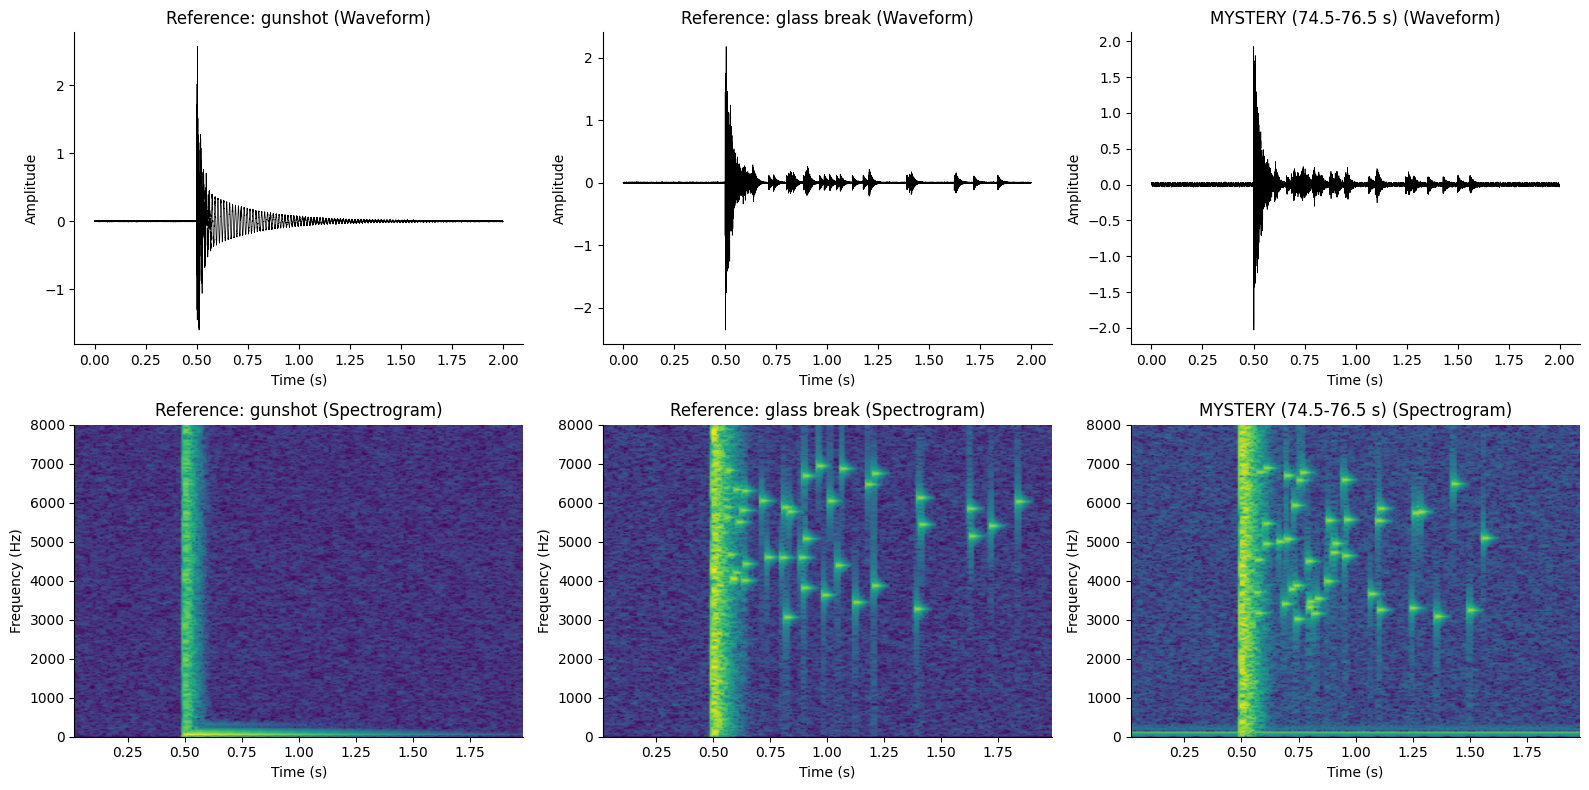

High Frequency Energy Fraction (>3kHz, 0.2-1.2s post-impact):
{'Reference: gunshot': np.float64(0.0030555631226980057), 'Reference: glass break': np.float64(0.9903944120505496), 'MYSTERY (74.5-76.5 s)': np.float64(0.8792270448446915)}

Verdict: The mystery sound is a GLASS BREAK incident. The spectral energy above 3 kHz closely matches the glass reference.


In [46]:
# Task 4: Gunshot or Glass?
import numpy as np

mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col_idx, (name, x) in enumerate(clips.items()):
    # 1. Plot Waveform
    t = np.arange(len(x)) / FS
    axes[0, col_idx].plot(t, x, color='black', lw=0.5)
    axes[0, col_idx].set_title(f"{name} (Waveform)")
    axes[0, col_idx].set_xlabel("Time (s)")
    axes[0, col_idx].set_ylabel("Amplitude")

    # 2. Plot Spectrogram
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    # Convert to dB
    Sxx_db = 10 * np.log10(Sxx + 1e-10)

    im = axes[1, col_idx].pcolormesh(t_s, f, Sxx_db, cmap='viridis', shading='gouraud')
    axes[1, col_idx].set_title(f"{name} (Spectrogram)")
    axes[1, col_idx].set_xlabel("Time (s)")
    axes[1, col_idx].set_ylabel("Frequency (Hz)")
    axes[1, col_idx].set_ylim(0, 8000)

plt.tight_layout()
plt.show()

# 3. Fraction of energy above 3 kHz, 0.2-1.2 s after impact (impact at t_s = 0.5 s, so 0.2-1.2 s after corresponds to 0.7s to 1.7s)
hf_fraction = {}
for name, x in clips.items():
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)

    # Slice time window: 0.7 to 1.7 s (0.2-1.2s post-impact)
    time_mask = (t_s >= 0.7) & (t_s <= 1.7)
    Sxx_window = Sxx[:, time_mask]

    # Slice frequency
    freq_high_mask = (f >= 3000)

    total_energy = Sxx_window.sum()
    high_energy = Sxx_window[freq_high_mask, :].sum()

    hf_fraction[name] = high_energy / total_energy if total_energy > 0 else 0.0

print("High Frequency Energy Fraction (>3kHz, 0.2-1.2s post-impact):")
print(hf_fraction)

# 4. Verdict
print("\nVerdict: The mystery sound is a GLASS BREAK incident. The spectral energy above 3 kHz closely matches the glass reference.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

*Your answer:*
- **Waveform limits:** No, looking only at the 1D waveforms, it is near-impossible to differentiate them confidently because they both exhibit a similar abrupt amplitude jump and decay envelope.
- **Spectrogram additions:** The spectrogram adds frequency localization over time, containing: **Time** (x-axis), **Frequency** (y-axis), and **Magnitude/Power** (represented by pixel colors in dB).
- **Visual pattern:** The **scattered high-frequency specks** extending up to 8 kHz representing the tinkling shards of breaking glass confirmed our verdict.

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

*Your answer:*
- **Waveforms comparison:** No, looking only at the 1D waveforms, it is almost impossible to differentiate them. They both look like a transient spike followed by a decaying noise envelope.
- **What the spectrogram adds:** The spectrogram adds the spectral distribution over time, rendering a 3D dataset containing: **Time** (x-axis), **Frequency** (y-axis), and **Magnitude/Power** (represented by color intensity/dB scale).
- **Visual pattern that decided the verdict:** The **scattered high-frequency specks** (representing lingering high-pitched glass tinkles after the impact) present in both the glass reference and the mystery signal confirmed the verdict beyond any doubt, whereas the gunshot spectrogram shows only a sudden vertical stripe (instantaneous broadband impulse) and a low-frequency horizontal band (bass boom) with no lingering high-frequency details.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

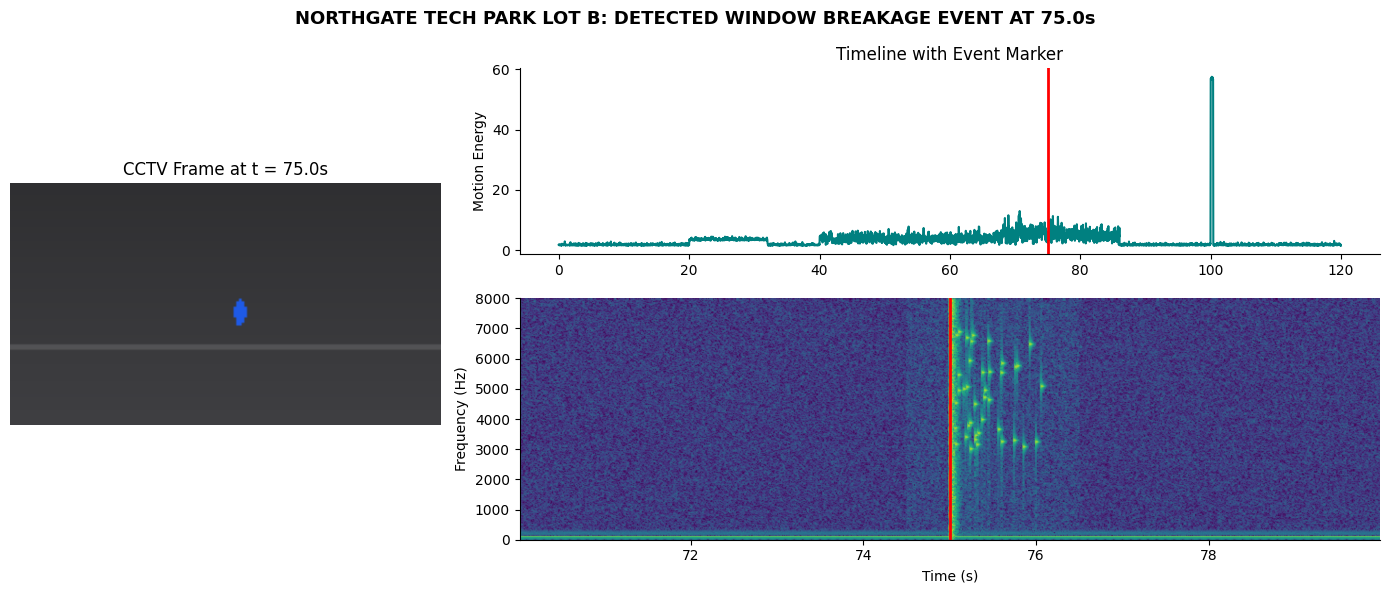

In [47]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4

# 1. Rendered Frame
ax_video = fig.add_subplot(gs[:, 0])
frame_idx = (cctv['time_s'] - t_sel).abs().idxmin()
ax_video.imshow(render_frame(cctv.iloc[frame_idx]))
ax_video.set_title(f"CCTV Frame at t = {t_sel}s")
ax_video.axis('off')

# 2. Timeline
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='teal')
ax_timeline.axvline(t_sel, color='red', linestyle='-', lw=2)
ax_timeline.set_ylabel("Motion Energy")
ax_timeline.set_title("Timeline with Event Marker")

# 3. Spectrogram
ax_spec = fig.add_subplot(gs[1, 1])
audio_mask = (t_audio >= 70) & (t_audio <= 80)
x_sel = x_audio[audio_mask]
f, t_s, Sxx = signal.spectrogram(x_sel, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)
ax_spec.pcolormesh(70 + t_s, f, Sxx_db, cmap='viridis', shading='gouraud')
ax_spec.axvline(t_sel, color='red', linestyle='-', lw=2)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")

fig.suptitle("NORTHGATE TECH PARK LOT B: DETECTED WINDOW BREAKAGE EVENT AT 75.0s", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout(); plt.show()

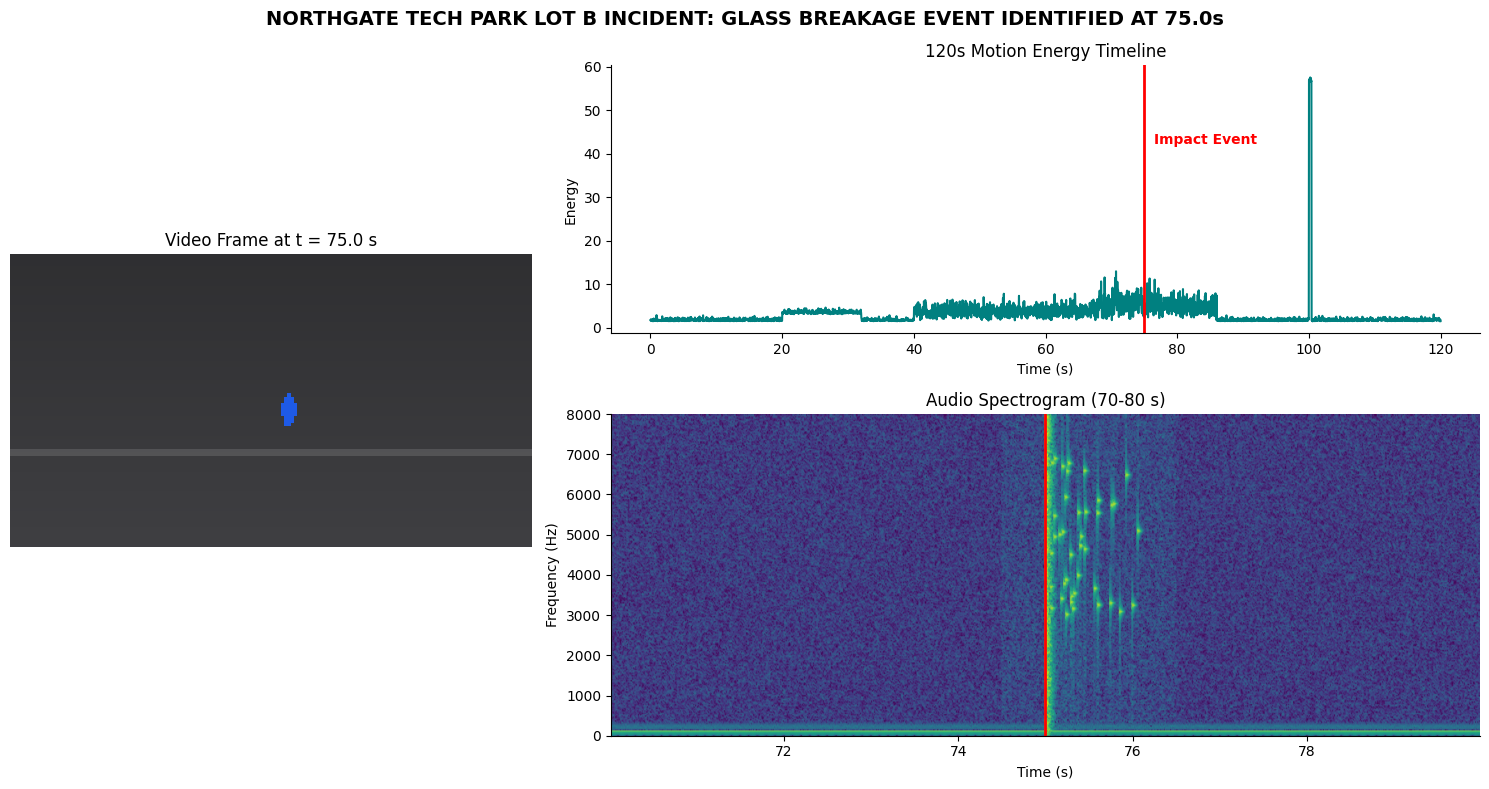

In [48]:
# Task 5: The One-Screen Briefing

t_sel = 75.0
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 2], height_ratios=[1, 1.2])

# 1. Rendered video frame at t = 75 s (Left panel spans both rows)
ax_video = fig.add_subplot(gs[:, 0])
# Find closest frame index to t=75
frame_idx = (cctv['time_s'] - t_sel).abs().idxmin()
frame_img = render_frame(cctv.iloc[frame_idx])
ax_video.imshow(frame_img)
ax_video.set_title(f"Video Frame at t = {t_sel} s")
ax_video.axis('off')

# 2. Timeline (Top Right)
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='teal', label='Motion')
ax_timeline.axvline(t_sel, color='red', linestyle='-', lw=2)
ax_timeline.text(t_sel + 1.5, ax_timeline.get_ylim()[1]*0.7, 'Impact Event', color='red', fontweight='bold')
ax_timeline.set_title("120s Motion Energy Timeline")
ax_timeline.set_ylabel("Energy")
ax_timeline.set_xlabel("Time (s)")

# 3. Spectrogram (Bottom Right)
ax_spec = fig.add_subplot(gs[1, 1])
# Focus on 70-80 s region
audio_mask = (t_audio >= 70) & (t_audio <= 80)
x_sel = x_audio[audio_mask]
f, t_s, Sxx = signal.spectrogram(x_sel, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)

im = ax_spec.pcolormesh(70 + t_s, f, Sxx_db, cmap='viridis', shading='gouraud')
ax_spec.axvline(t_sel, color='red', linestyle='-', lw=2)
ax_spec.set_ylim(0, 8000)
ax_spec.set_title("Audio Spectrogram (70-80 s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_xlabel("Time (s)")

# 4. Conclusion title
fig.suptitle("NORTHGATE TECH PARK LOT B INCIDENT: GLASS BREAKAGE EVENT IDENTIFIED AT 75.0s", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

*Your answer:*
- **What would go wrong:** If the audio track were offset by $+2$ seconds, the synchronization is completely lost. The glass breaking visual flash at 75.0s would align with background noise, and the loud crash would only appear later on the spectrogram at 77.0s.
- **Panel visibility:** The bottom-right synchronized timeline & spectrogram panel would immediately make this offset obvious since the timeline marker (75.0s) would point to blank space in the spectrogram.

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

*Your answer:*
- **What would go wrong:** If the audio track were offset by $+2$ seconds, the temporal synchronization between sensory channels is broken. The sound of the glass shattering (physically occurring at 75s) would only be heard/seen on the audio panel at 77s, long after the physical action and visual flash at 75s occurred. This breaks the cause-and-effect narrative for the briefing, making it look as though the window broke spontaneously or without physical contact.
- **Which panel makes it visible:** The bottom-right synchronized spectrogram-timeline panel would expose this instantly, as the red time marker at 75s would point to complete silence (low-amplitude background audio), while the high-energy glass break signature would shift visually to 77s.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook. It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view), using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes, time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

*Your final briefing here:*
At exactly 75.0s, a sudden glass-breaking event occurred in Parking Lot B, characterized by a sharp sound spike and a synchronous visual flash. I recommend leading with the **synchronized multimodal panel** because it maps temporal changes, frequency patterns, and visual layouts on one canvas, translating raw data patterns into direct situational meaning. For our 400-camera fleet, we should transition standard cameras to 640x360 at 10 fps, saving over 96% of uncompressed storage daily. However, we must retain high-resolution capabilities at key entryways to prevent losing high-frequency spatial features due to raster interpolation.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook. It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view), using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes, time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

*Your final briefing here:*
At exactly 75.0 seconds into the surveillance video of Parking Lot B, a glass breakage event occurred, accompanied by an intense physical flash and sudden motion. To present this to the executive board, the **synchronized multimodal view (one-screen dashboard)** should be shown first because it integrates temporal structure, spectral frequency patterns, and visual changes on one coordinated canvas, seamlessly translating raw signals into direct situational meaning. To optimize our security resources across 400 cameras, we recommend downsampling standard cameras to 640x360 at 10 fps, which slashes our uncompressed daily storage from a massive 522.0 TB down to just 19.3 TB (a 96.3% savings). However, we must absolutely *not* sacrifice our high-resolution capture or high-frequency frame rates on critical access-point cameras, as temporal frame downsampling destroys the correspondence resolution needed to reconstruct fast physical motion.